# Kriteria 1 (Advanced) — GRPO: Melatih Model Menalar dengan `<think>`

**Submission PGABL — Fepriyadi Harahap**

Model hasil SFT (notebook Fine-tuning) dimuat ulang dari Hugging Face lalu dilatih dengan
**GRPO** (`GRPOTrainer` dari TRL, dioptimasi Unsloth). Model belajar menuliskan proses berpikir di dalam
`<think> ... </think>` sebelum memberi jawaban akhir berbahasa Indonesia.

```text
SFT model (Hugging Face)
    └── QLoRA 4-bit + adapter LoRA baru
          └── GRPOTrainer
                ├── format_reward_func       (reward shaping format <think>)
                ├── reasoning_length_reward  (panjang isi <think>)
                ├── correctness_reward       (ground truth / ROUGE-L terhadap kolom output)
                └── language_reward_func     (Bahasa Indonesia vs Inggris)
```

Dataset yang dipakai tetap `Ichsan2895/alpaca-gpt4-indonesian`; kolom `output` menjadi ground truth.

## 0. Instalasi & Import

In [1]:
%%capture
!pip install -q unsloth rouge_score

In [2]:
from unsloth import FastLanguageModel, is_bfloat16_supported
from unsloth.chat_templates import get_chat_template

import gc
import os
import random
import re

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import load_dataset
from rouge_score import rouge_scorer
from transformers import BitsAndBytesConfig, TextStreamer
from trl import GRPOConfig, GRPOTrainer

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [3]:
assert torch.cuda.is_available(), "Notebook ini membutuhkan GPU CUDA (Colab T4 / Kaggle T4 / P100)."
gpu = torch.cuda.get_device_properties(0)
GPU_TOTAL_GB = round(gpu.total_memory / 1024**3, 2)
print(f"GPU: {gpu.name} | VRAM: {GPU_TOTAL_GB} GB | bf16 didukung: {is_bfloat16_supported()}")

GPU: Tesla T4 | VRAM: 14.56 GB | bf16 didukung: False


In [4]:
from huggingface_hub import login, whoami
from kaggle_secrets import UserSecretsClient


def get_hf_token():
    """Token Hugging Face (akses write) dari Colab Secrets / Kaggle Secrets / env var / input manual."""
    try:
        from google.colab import userdata
        token = userdata.get("HF_TOKEN")
        if token:
            return token
    except Exception:
        pass
    try:
        hf_token = UserSecretsClient().get_secret("HF_TOKEN")
        return hf_token
    except Exception:
        pass
    if os.environ.get("HF_TOKEN"):
        return os.environ["HF_TOKEN"]
    from getpass import getpass
    return getpass("Masukkan Hugging Face token (write): ")


HF_TOKEN = get_hf_token()
login(token=HF_TOKEN)
HF_USERNAME = whoami(token=HF_TOKEN)["name"]
print("Login Hugging Face sebagai:", HF_USERNAME)

Login Hugging Face sebagai: Fepriyadi


In [5]:
BASE_MODEL = "unsloth/Qwen2.5-3B-Instruct"   # arsitektur Qwen2 (didukung Unsloth), task: Text Generation
SFT_REPO = f"{HF_USERNAME}/Qwen2.5-3B-Instruct-Alpaca-ID-SFT"     # hasil Kriteria 1 (SFT)
GRPO_REPO = f"{HF_USERNAME}/Qwen2.5-3B-Instruct-Alpaca-ID-GRPO"   # hasil Kriteria 1 Advanced (GRPO)
SEED = 3407

THINK_SYSTEM_PROMPT = (
    "Anda adalah asisten AI berbahasa Indonesia. Sebelum menjawab, tuliskan proses berpikir Anda "
    "langkah demi langkah di dalam tag <think> ... </think>. Setelah tag </think>, tuliskan jawaban akhir "
    "yang jelas dan ringkas dalam Bahasa Indonesia.\n"
    "Format:\n<think>\nproses berpikir\n</think>\njawaban akhir"
)

MAX_SEQ_LENGTH = 1024
MAX_PROMPT_TOKENS = 256        # prompt lebih panjang dibuang dari dataset (GRPOConfig TRL >= 0.28 tidak punya max_prompt_length)
MAX_COMPLETION_LENGTH = 384    # batas token jawaban per generation -> kunci mencegah OOM
NUM_GENERATIONS = 4            # jumlah kandidat jawaban per prompt (grup GRPO) -> kunci mencegah OOM
GRPO_STEPS = 150
THINK_PREFILL = "<think>\n"     # awal giliran assistant pada sebagian prompt GRPO
PREFILL_RATIO = 0.5            # porsi prompt yang diberi prefill; sisanya harus membuka <think> sendiri
print("Model awal (SFT):", SFT_REPO)
print("Repo tujuan GRPO:", GRPO_REPO)

Model awal (SFT): Fepriyadi/Qwen2.5-3B-Instruct-Alpaca-ID-SFT
Repo tujuan GRPO: Fepriyadi/Qwen2.5-3B-Instruct-Alpaca-ID-GRPO


## 1. Memuat Kembali Model Instruct Hasil SFT (QLoRA)

Model `SFT_REPO` adalah hasil `push_to_hub_merged(..., "merged_16bit")` dari notebook Fine-tuning.
Model dimuat lagi dalam 4-bit dengan double quantization, lalu diberi adapter LoRA baru untuk GRPO.

In [6]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16 if is_bfloat16_supported() else torch.float16,
)

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=SFT_REPO,
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=None,
    load_in_4bit=True,
    quantization_config=bnb_config,
    use_exact_model_name=True,
    fast_inference=False,
    token=HF_TOKEN,
)
tokenizer = get_chat_template(tokenizer, chat_template="qwen-2.5")

model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    lora_alpha=32,
    lora_dropout=0.0,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=SEED,
)
model.print_trainable_parameters()

==((====))==  Unsloth 2026.10.7: Fast Qwen2 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Unsloth 2026.10.7 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


## 2. Dataset Prompt untuk GRPO

GRPO hanya butuh *prompt*; model membuat jawabannya sendiri lalu dinilai oleh reward function.
Kolom `output` disimpan sebagai `answer` (ground truth) untuk `correctness_reward`.

Filter yang dipakai:
- panjang `output` 20–500 karakter → ground truth realistis untuk dibandingkan dalam `MAX_COMPLETION_LENGTH`;
- prompt ≤ `MAX_PROMPT_TOKENS` token → pengganti `max_prompt_length`.

**Prefill parsial.** Model SFT hampir tidak pernah membuka `<think>` sendiri (1 dari 600 sampel pada run
sebelumnya), sehingga reward format bernilai sama di seluruh grup dan GRPO tidak mendapat sinyal.
Sebanyak `PREFILL_RATIO` prompt diberi pesan assistant `"<think>\n"` di akhir; TRL melanjutkan pesan itu
(`continue_final_message`) sehingga keempat kandidat sudah berada di dalam blok penalaran dan belajar
menulis isi serta menutup `</think>`. Sisa prompt tanpa prefill menguji apakah model membuka tag secara alami.

In [7]:
raw_dataset = load_dataset("Ichsan2895/alpaca-gpt4-indonesian", split="train")


def split_alpaca_input(text):
    instruction, _, context = text.strip().partition("\n")
    return instruction.strip(), context.strip()


def to_grpo_prompt(row):
    instruction, context = split_alpaca_input(row["input"])
    user_content = f"{instruction}\n\nInput:\n{context}" if context else instruction
    return {
        "prompt": [
            {"role": "system", "content": THINK_SYSTEM_PROMPT},
            {"role": "user", "content": user_content},
        ],
        "answer": row["output"].strip(),
    }


def with_think_prefill(messages):
    """Giliran assistant diawali "<think>\n"; TRL & generate() melanjutkan pesan ini (continue_final_message)."""
    return messages + [{"role": "assistant", "content": THINK_PREFILL}]


grpo_dataset = (
    raw_dataset.filter(lambda row: 20 <= len(row["output"].strip()) <= 500)
    .shuffle(seed=SEED)
    .select(range(3000))
    .map(to_grpo_prompt, remove_columns=raw_dataset.column_names)
)
def prompt_tokens(messages):
    text = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
    return len(tokenizer(text, add_special_tokens=False)["input_ids"])


grpo_dataset = grpo_dataset.filter(lambda row: prompt_tokens(row["prompt"]) <= MAX_PROMPT_TOKENS)

# Prefill dipasang setelah filter token karena prompt_tokens memakai add_generation_prompt=True.
prefill_idx = set(random.Random(SEED).sample(range(len(grpo_dataset)), k=round(PREFILL_RATIO * len(grpo_dataset))))
grpo_dataset = grpo_dataset.map(
    lambda row, i: {"prompt": with_think_prefill(row["prompt"]) if i in prefill_idx else row["prompt"]},
    with_indices=True,
)
print(grpo_dataset)
print(f"Prompt dengan prefill {THINK_PREFILL!r}: {len(prefill_idx)} dari {len(grpo_dataset)}")
grpo_dataset[0]

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

alpaca-gpt4-indonesia.csv: reconstructing file:   0%|          |  0.00B / 41.4MB            

alpaca-gpt4-indonesia.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/49969 [00:00<?, ? examples/s]

Filter:   0%|          | 0/49969 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2989 [00:00<?, ? examples/s]

Dataset({
    features: ['prompt', 'answer'],
    num_rows: 2989
})
Prompt dengan prefill '<think>\n': 1494 dari 2989


{'prompt': [{'content': 'Anda adalah asisten AI berbahasa Indonesia. Sebelum menjawab, tuliskan proses berpikir Anda langkah demi langkah di dalam tag <think> ... </think>. Setelah tag </think>, tuliskan jawaban akhir yang jelas dan ringkas dalam Bahasa Indonesia.\nFormat:\n<think>\nproses berpikir\n</think>\njawaban akhir',
   'role': 'system'},
  {'content': 'Jelaskan rasa es krim Butterscotch dalam 5 kata.',
   'role': 'user'}],
 'answer': 'Manis, krimi, berbuttery, kaya rasa, karamelisasi.'}

## 3. Reward Functions

Semua fungsi menerima `completions` dari `GRPOTrainer` (format percakapan: `[{"role": "assistant", "content": ...}]`)
dan mengembalikan satu skor per completion. Kolom dataset lain (mis. `answer`) diteruskan sebagai keyword argument.

### Helper: ekstraksi `<think>` dan jawaban akhir

`extract_thinking` tetap mengambil isi penalaran walau `</think>` belum muncul karena terpotong
`max_completion_length`.

In [8]:
THINK_OPEN, THINK_CLOSE = "<think>", "</think>"


def completion_text(completion):
    """GRPOTrainer mengirim completion sebagai list pesan (format percakapan) atau string biasa."""
    if isinstance(completion, list):
        return completion[0]["content"] if completion else ""
    return completion


def extract_thinking(text):
    """Isi <think>...</think>. Toleran terhadap penalaran yang terpotong max_completion_length (tanpa </think>)."""
    if THINK_OPEN not in text:
        return ""
    after_open = text.split(THINK_OPEN, 1)[1]
    return after_open.split(THINK_CLOSE, 1)[0].strip()


def extract_final_answer(text):
    """Jawaban akhir = teks setelah </think> terakhir.
    Ada <think> tapi tidak ditutup -> model belum selesai berpikir -> belum ada jawaban akhir.
    Tidak ada tag sama sekali -> seluruh teks dianggap jawaban."""
    if THINK_CLOSE in text:
        return text.rsplit(THINK_CLOSE, 1)[1].strip()
    if THINK_OPEN in text:
        return ""
    return text.strip()


PERFECT_FORMAT_RE = re.compile(r"^<think>(?P<think>\s*\S.*?)</think>\s*(?P<answer>\S.*)$", re.DOTALL)


def prefill_aware(reward_func):
    """Reward function menilai teks lengkap termasuk prefill "<think>\n".
    TRL biasanya sudah menyambung prefill ke completion (dan membuangnya dari prompt);
    wrapper ini hanya menyambung bila belum, agar hasil tidak bergantung pada versi TRL/Unsloth."""
    def wrapped(prompts, completions, **kwargs):
        full = []
        for prompt, completion in zip(prompts, completions):
            text = completion_text(completion)
            if prompt[-1]["role"] == "assistant" and not text.startswith(prompt[-1]["content"]):
                text = prompt[-1]["content"] + text
            full.append([{"role": "assistant", "content": text}])
        return reward_func(completions=full, **kwargs)

    wrapped.__name__ = reward_func.__name__
    return wrapped

### `format_reward_func` — reward shaping (maks +1.0)

| Kondisi | Poin |
|---|---|
| Membuka respons dengan `<think>` | +0.2 |
| Menutup pemikiran dengan `</think>` | +0.3 |
| Format sempurna: `<think>` di awal, isi tidak kosong, ditutup, lalu ada jawaban akhir | 1.0 (maksimum) |
| `<think>` atau `</think>` muncul lebih dari sekali (halusinasi tag) | −0.5 |

In [9]:
def format_reward_func(completions, **kwargs):
    """Reward shaping format <think>: +0.2 buka tag, +0.3 tutup tag, format sempurna = 1.0 (maksimum),
    -0.5 jika tag <think> / </think> muncul lebih dari sekali."""
    rewards = []
    for completion in completions:
        text = completion_text(completion).strip()
        n_open, n_close = text.count(THINK_OPEN), text.count(THINK_CLOSE)
        if n_open == 1 and n_close == 1 and PERFECT_FORMAT_RE.match(text):
            rewards.append(1.0)
            continue
        score = 0.0
        if n_open >= 1:
            score += 0.2
        if n_close >= 1:
            score += 0.3
        if n_open > 1 or n_close > 1:
            score -= 0.5
        rewards.append(round(score, 2))
    return rewards

### `reasoning_length_reward` — panjang isi `<think>`

| Isi `<think>` | Poin |
|---|---|
| Tidak ada tag / isi kosong / hanya spasi | 0.0 |
| < 50 karakter | 0.2 |
| 50–199 karakter | 0.5 |
| ≥ 200 karakter | 1.0 |

In [10]:
def reasoning_length_reward(completions, **kwargs):
    """Poin proporsional panjang isi <think>: kosong 0.0, <50 karakter 0.2, 50-199 0.5, >=200 1.0."""
    rewards = []
    for completion in completions:
        n_chars = len(extract_thinking(completion_text(completion)))
        if n_chars == 0:
            rewards.append(0.0)
        elif n_chars < 50:
            rewards.append(0.2)
        elif n_chars < 200:
            rewards.append(0.5)
        else:
            rewards.append(1.0)
    return rewards

### `correctness_reward` — ground truth / ROUGE-L

+1.0 jika jawaban akhir (setelah `</think>`) memuat ground truth dari kolom `output`, atau ROUGE-L F1 ≥ 0.4.
Di bawah threshold diberikan nilai ROUGE-L sebagai kredit parsial agar sinyal belajar tidak selalu nol.

In [11]:
_rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=False)
ROUGE_THRESHOLD = 0.4


def _normalize(text):
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", text.lower())).strip()


def correctness_reward(completions, answer, **kwargs):
    """+1.0 jika jawaban akhir memuat ground truth (kolom output) atau ROUGE-L F1 >= ROUGE_THRESHOLD.
    Di bawah threshold diberi nilai ROUGE-L itu sendiri (kredit parsial) agar sinyal belajar tidak nol."""
    rewards = []
    for completion, truth in zip(completions, answer):
        final = extract_final_answer(completion_text(completion))
        if not final:
            rewards.append(0.0)
            continue
        final_norm, truth_norm = _normalize(final), _normalize(truth)
        if truth_norm and truth_norm in final_norm:
            rewards.append(1.0)
            continue
        rouge_l = _rouge.score(truth, final)["rougeL"].fmeasure
        rewards.append(1.0 if rouge_l >= ROUGE_THRESHOLD else round(rouge_l, 3))
    return rewards

### `language_reward_func` — Bahasa Indonesia

Bahasa jawaban akhir dideteksi dari proporsi *stopword* Indonesia vs Inggris.

```text
rasio kata Inggris >= 0.30  ->  -0.5  (model tiba-tiba menjawab dalam Bahasa Inggris)
rasio kata Inggris <= 0.05  ->  +1.0  (murni Bahasa Indonesia)
di antaranya                ->   0.0  (campuran)
```

In [12]:
ID_WORDS = set("""yang dan di ke dari ini itu dengan untuk tidak adalah dalam akan pada juga saya anda kami kita
atau ada bisa dapat sebagai oleh karena jika maka sudah telah harus wajib berhak tersebut lebih agar seperti
bahwa hal para bagi serta namun tetapi sehingga setiap hanya sangat merupakan yaitu ya dia mereka apa bagaimana
mengapa kapan dimana berapa banyak sebuah satu dua tiga""".split())
EN_WORDS = set("""the and is are was were of to in that this it with for on be by an or not you your we they
have has can will would should which what there their from at but if so do does these those because also yes
how why when where who been being about into than then them our its""".split())


# Kode program dan teks dalam tanda kutip (judul buku/film/lagu) bukan bahasa jawaban model -> diabaikan.
NON_PROSE_RE = re.compile(r"```.*?```|`[^`]*`|\"[^\"]*\"|“[^”]*”|'[^'\n]{2,}'", re.DOTALL)


def language_reward_func(completions, **kwargs):
    """+1.0 jika jawaban akhir murni Bahasa Indonesia, -0.5 jika didominasi Bahasa Inggris, 0.0 jika campuran.
    ("as" tidak dihitung sebagai kata Inggris karena "AS" = Amerika Serikat.)"""
    rewards = []
    for completion in completions:
        prose = NON_PROSE_RE.sub(" ", extract_final_answer(completion_text(completion)))
        words = re.findall(r"[a-z]+", prose.lower())
        id_hits = sum(w in ID_WORDS for w in words)
        en_hits = sum(w in EN_WORDS for w in words)
        if id_hits + en_hits == 0:
            rewards.append(0.0)
            continue
        en_ratio = en_hits / (id_hits + en_hits)
        if en_hits >= 2 and en_ratio >= 0.3:
            rewards.append(-0.5)
        elif en_ratio <= 0.05:
            rewards.append(1.0)
        else:
            rewards.append(0.0)
    return rewards

### Uji reward functions pada contoh buatan

In [13]:
long_think = ("User adalah staf admin, artinya pekerja non-manajerial. Berdasarkan PP 35/2021, pekerja yang "
              "bekerja melebihi waktu kerja standar wajib dibayar upah lembur. Lembur 3 jam masih di bawah batas "
              "maksimal 4 jam per hari, jadi lembur tersebut sah dan harus dibayar.")
gt = "Ya, Anda berhak mendapatkan upah lembur karena bekerja melebihi waktu kerja normal."
cases = {
    "sempurna": f"<think>{long_think}</think> Ya, Anda berhak mendapatkan upah lembur karena bekerja melebihi waktu kerja normal.",
    "tanpa tag": "Ya, Anda berhak atas upah lembur.",
    "hanya buka (terpotong)": "<think>Saya perlu menganalisis pertanyaan ini terlebih dahulu dengan teliti sebelum",
    "tutup tanpa buka": "Pertanyaan tentang lembur.</think> Ya, berhak.",
    "tag ganda": "<think>a</think><think>b</think> Ya, Anda berhak.",
    "think kosong": "<think>   </think> Ya, Anda berhak.",
    "jawab Inggris": f"<think>{long_think}</think> Yes, you are entitled to overtime pay because you worked more than the normal hours.",
    "think pendek": "<think>Lembur 3 jam, wajib dibayar.</think> Ya, Anda berhak atas upah lembur.",
}
comps = [[{"role": "assistant", "content": c}] for c in cases.values()]
answers = [gt] * len(comps)
cols = {
    "format": format_reward_func(comps),
    "len": reasoning_length_reward(comps),
    "correct": correctness_reward(comps, answer=answers),
    "lang": language_reward_func(comps),
}
display(pd.DataFrame(cols, index=list(cases)))

# prefill_aware: completion dari prompt ber-prefill (tanpa "<think>" di awal) tetap dinilai format sempurna.
prefilled = [with_think_prefill([{"role": "user", "content": "Apakah saya berhak dapat uang lembur?"}])]
no_open_tag = [[{"role": "assistant", "content": f"{long_think}</think> Ya, Anda berhak."}]]
print("format tanpa wrapper :", format_reward_func(no_open_tag))
print("format dengan wrapper:", prefill_aware(format_reward_func)(prompts=prefilled, completions=no_open_tag))

,format,len,correct,lang
sempurna,1.0,1.0,1.000,1.0
tanpa tag,0.0,0.0,1.000,1.0
hanya buka (terpotong),0.2,0.5,0.000,0.0
tutup tanpa buka,0.3,0.0,0.286,1.0
tag ganda,0.0,0.2,1.000,1.0
think kosong,0.5,0.0,1.000,1.0
jawab Inggris,1.0,1.0,0.074,-0.5
think pendek,1.0,0.2,1.000,1.0


format tanpa wrapper : [0.3]
format dengan wrapper: [1.0]


### Bersihkan prompt yang ground truth-nya sendiri berbahasa Inggris

Sebagian kecil jawaban GPT-4 di dataset tidak ikut diterjemahkan (mis. ekor esai berbahasa Inggris, daftar judul
Inggris, query SQL). Pada baris seperti itu `correctness_reward` mendorong model meniru teks Inggris sementara
`language_reward_func` menghukumnya. Sinyalnya saling bertentangan, jadi baris tersebut dibuang.

In [14]:
as_completion = lambda text: [[{"role": "assistant", "content": text}]]
before = len(grpo_dataset)
grpo_dataset = grpo_dataset.filter(lambda row: language_reward_func(as_completion(row["answer"]))[0] > -0.5)
print(f"Prompt GRPO: {len(grpo_dataset)} (dibuang {before - len(grpo_dataset)} baris ground truth berbahasa Inggris)")

Filter:   0%|          | 0/2989 [00:00<?, ? examples/s]

Prompt GRPO: 2963 (dibuang 26 baris ground truth berbahasa Inggris)


## 4. Perilaku Model Sebelum GRPO

Sampel singkat sebagai pembanding: apakah model SFT sudah mengikuti format `<think>` tanpa GRPO?

In [15]:
def generate(messages, max_new_tokens=384, temperature=0.3, stream=False):
    prefill = messages[-1]["role"] == "assistant"
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=not prefill, continue_final_message=prefill, return_tensors="pt", return_dict=True
    ).to("cuda")
    streamer = TextStreamer(tokenizer, skip_prompt=True, skip_special_tokens=True) if stream else None
    output = model.generate(
        **inputs, max_new_tokens=max_new_tokens, temperature=temperature, top_p=0.9, do_sample=True,
        streamer=streamer,
    )
    text = tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return messages[-1]["content"] + text if prefill else text


def show_samples(prompts, temperature):
    """Tiap prompt diuji dua mode: alami (model harus membuka <think> sendiri) dan dengan prefill "<think>\n"."""
    for p in prompts:
        print("PROMPT :", p[-1]["content"][:200])
        for label, messages in [("alami", p), ("prefill", with_think_prefill(p))]:
            out = generate(messages, temperature=temperature)
            print(f"OUTPUT [{label}] :", out)
            print("reward :", {f.__name__: f([[{"role": "assistant", "content": out}]])[0]
                               for f in [format_reward_func, reasoning_length_reward, language_reward_func]})
        print("-" * 100)


LEMBUR_PROMPT = "Saya staf admin, kemarin lembur 3 jam untuk beresin laporan. Apakah saya berhak dapat uang lembur?"
sample_prompts = [
    [m for m in grpo_dataset[0]["prompt"] if m["role"] != "assistant"],
    [{"role": "system", "content": THINK_SYSTEM_PROMPT}, {"role": "user", "content": LEMBUR_PROMPT}],
]

FastLanguageModel.for_inference(model)
show_samples(sample_prompts, temperature=0.3)
FastLanguageModel.for_training(model)

PROMPT : Jelaskan rasa es krim Butterscotch dalam 5 kata.


Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


OUTPUT [alami] : Terasa manis, lembut, dan lezat.
reward : {'format_reward_func': 0.0, 'reasoning_length_reward': 0.0, 'language_reward_func': 1.0}


Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


OUTPUT [prefill] : <think>
Rasa es krim Butterscotch biasanya memiliki rasa manis dan lezat dengan sedikit gurih dan keju.
</think>
Rasa es krim Butterscotch adalah manis dan lezat.
reward : {'format_reward_func': 1.0, 'reasoning_length_reward': 0.5, 'language_reward_func': 1.0}
----------------------------------------------------------------------------------------------------
PROMPT : Saya staf admin, kemarin lembur 3 jam untuk beresin laporan. Apakah saya berhak dapat uang lembur?


Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


OUTPUT [alami] : Sebagai staf admin, Anda mungkin memiliki hak untuk mendapatkan uang lembur tergantung pada aturan dan kebijakan perusahaan Anda. Penting untuk mengecek dengan manajemen atau HR untuk memastikan bahwa Anda telah diberi tahu tentang hak dan persyaratan untuk mendapatkan uang lembur. Jika Anda telah diberitahu bahwa Anda berhak mendapatkan uang lembur, Anda harus mengajukan permohonan untuk uang lembur sesuai dengan prosedur yang ditetapkan oleh perusahaan.
reward : {'format_reward_func': 0.0, 'reasoning_length_reward': 0.0, 'language_reward_func': 1.0}
OUTPUT [prefill] : <think>
Sebagai staf admin, Anda mungkin memiliki hak untuk mengambil uang lembur jika Anda telah menginformasikan perusahaan bahwa Anda akan bekerja lebih dari waktu kerja standar sebelumnya. Namun, aturan dan kebijakan tentang uang lembur dapat bervariasi dari satu perusahaan ke perusahaan lainnya. Penting untuk memeriksa dengan manajemen atau kantor HR untuk mengetahui apakah Anda berhak mengambil ua

PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): Qwen2ForCausalLM(
      (model): Qwen2Model(
        (embed_tokens): Embedding(151936, 2048, padding_idx=151654)
        (layers): ModuleList(
          (0-35): 36 x Qwen2DecoderLayer(
            (self_attn): Qwen2Attention(
              (q_proj): lora.Linear4bit(
                (base_layer): Linear4bit(in_features=2048, out_features=2048, bias=True)
                (lora_dropout): ModuleDict(
                  (default): Identity()
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=2048, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=16, out_features=2048, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()
              )
              (k_proj): lora

## 5. Training GRPO

Mitigasi OOM di T4 (16 GB):
- `num_generations=4` dan `per_device_train_batch_size=4` → satu prompt per step dengan 4 kandidat jawaban;
- `max_completion_length=384`, prompt dibatasi 256 token lewat filter dataset;
- model 4-bit + gradient checkpointing Unsloth; `optim="adamw_8bit"`.

In [16]:
training_args = GRPOConfig(
    output_dir="outputs_grpo",
    learning_rate=1e-5,
    adam_beta1=0.9,
    adam_beta2=0.99,
    weight_decay=0.1,
    warmup_steps=15,
    lr_scheduler_type="cosine",
    optim="adamw_8bit",
    logging_steps=1,
    per_device_train_batch_size=NUM_GENERATIONS,
    gradient_accumulation_steps=1,
    num_generations=NUM_GENERATIONS,
    max_completion_length=MAX_COMPLETION_LENGTH,
    temperature=0.9,
    max_steps=GRPO_STEPS,
    max_grad_norm=0.1,
    save_strategy="no",
    report_to="none",
    seed=SEED,
    fp16=not is_bfloat16_supported(),
    bf16=is_bfloat16_supported(),
)

trainer = GRPOTrainer(
    model=model,
    processing_class=tokenizer,
    reward_funcs=[prefill_aware(f) for f in
                  [format_reward_func, reasoning_length_reward, correctness_reward, language_reward_func]],
    args=training_args,
    train_dataset=grpo_dataset,
)

torch.cuda.reset_peak_memory_stats()
grpo_stats = trainer.train()
print(f"Puncak VRAM: {torch.cuda.max_memory_reserved() / 1024**3:.2f} GB dari {GPU_TOTAL_GB} GB")

Unsloth: GRPO now defaults to TRL's loss_type = 'dapo' with beta = 0.0. Set loss_type = 'bnpo', beta = 0.001 for Unsloth's previous default.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 2,963 | Num Epochs = 1 | Total steps = 150
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 1
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 1 x 1) = 4
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)
Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'cache_implementation'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / format_reward_func / mean,rewards / format_reward_func / std,rewards / reasoning_length_reward / mean,rewards / reasoning_length_reward / std,rewards / correctness_reward / mean,rewards / correctness_reward / std,rewards / language_reward_func / mean,rewards / language_reward_func / std
1,0.260750,0.463750,0.529551,75.750000,33.000000,118.000000,0.000000,75.750000,33.000000,118.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.213750,0.079105,0.250000,0.500000
2,-0.323845,1.162500,0.092425,79.250000,33.000000,113.000000,0.000000,79.250000,33.000000,113.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.162500,0.092425,1.000000,0.000000
3,0.168689,0.925750,0.498077,178.750000,143.000000,240.000000,0.000000,178.750000,143.000000,240.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.175750,0.030226,0.750000,0.500000
4,0.104269,1.454750,0.367016,121.000000,93.000000,140.000000,0.000000,121.000000,93.000000,140.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.454750,0.367016,1.000000,0.000000
5,-0.292908,0.625000,0.150000,21.750000,9.000000,31.000000,0.000000,21.750000,9.000000,31.000000,0.000000,0.200000,0.000000,0.425000,0.150000,0.000000,0.000000,0.000000,0.000000
6,0.430897,1.843750,0.312500,14.500000,8.000000,27.000000,0.000000,14.500000,8.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.843750,0.312500,1.000000,0.000000
7,-0.321395,1.682750,0.965500,154.000000,89.000000,253.000000,0.000000,154.000000,89.000000,253.000000,0.000000,0.400000,0.400000,1.000000,0.000000,0.032750,0.065500,0.250000,0.500000
8,-0.041076,1.009750,0.491756,102.000000,81.000000,144.000000,0.000000,102.000000,81.000000,144.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.259750,0.057656,0.750000,0.500000
9,0.583644,1.587750,0.477951,129.000000,33.000000,287.000000,0.000000,129.000000,33.000000,287.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.587750,0.477951,1.000000,0.000000
10,-1.298270,0.600000,0.400000,106.750000,13.000000,384.000000,0.250000,14.333334,13.000000,15.000000,0.000000,0.200000,0.000000,0.400000,0.400000,0.000000,0.000000,0.000000,0.000000


Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Puncak VRAM: 4.30 GB dari 14.56 GB


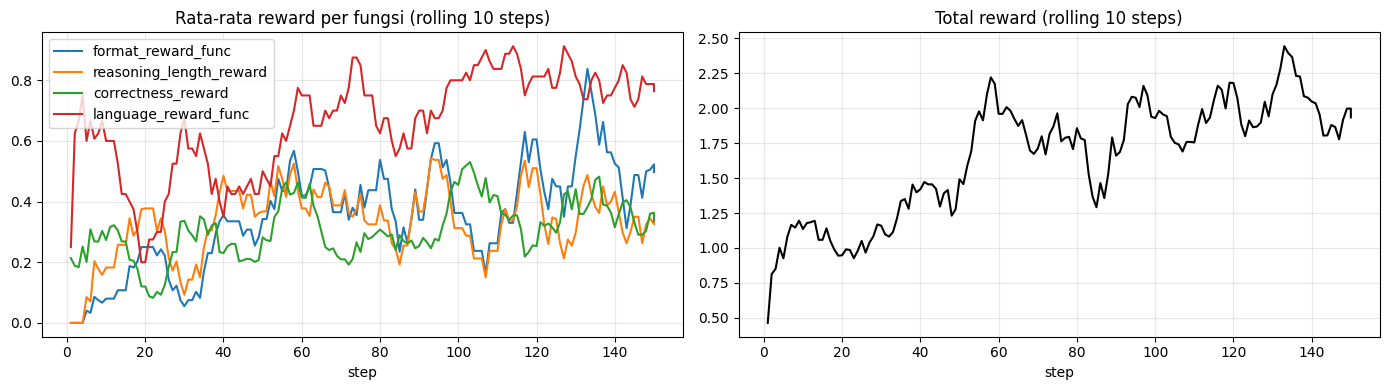

,20 step pertama,20 step terakhir
rewards/format_reward_func/mean,0.165,0.505
rewards/reasoning_length_reward/mean,0.280,0.353
rewards/correctness_reward/mean,0.197,0.348
rewards/language_reward_func/mean,0.400,0.783
reward,1.042,1.988


In [17]:
logs = pd.DataFrame(trainer.state.log_history)
reward_cols = [c for c in logs.columns if c.startswith("rewards/") and c.endswith("/mean")]
reward_cols = reward_cols or [c for c in logs.columns if c.startswith("rewards/") and not c.endswith("/std")]
total_col = "reward" if "reward" in logs.columns else None

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for col in reward_cols:
    axes[0].plot(logs["step"], logs[col].rolling(10, min_periods=1).mean(), label=col.split("/")[1])
axes[0].set_title("Rata-rata reward per fungsi (rolling 10 steps)")
axes[0].set_xlabel("step")
axes[0].legend()
axes[0].grid(alpha=0.3)
if total_col:
    axes[1].plot(logs["step"], logs[total_col].rolling(10, min_periods=1).mean(), color="black")
    axes[1].set_title("Total reward (rolling 10 steps)")
    axes[1].set_xlabel("step")
    axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

first, last = logs.head(20), logs.tail(20)
display(pd.DataFrame({
    "20 step pertama": first[reward_cols + ([total_col] if total_col else [])].mean(),
    "20 step terakhir": last[reward_cols + ([total_col] if total_col else [])].mean(),
}).round(3))

## 6. Uji Model Setelah GRPO

Termasuk test case wajib (tanpa RAG di sini; versi dengan dokumen UU/PP ada di notebook RAG).

Mode **alami** adalah bukti utama: model harus membuka `<think>` sendiri tanpa prefill.
Mode **prefill** menunjukkan kualitas isi penalaran dan apakah model menutup `</think>` dengan benar.

In [18]:
FastLanguageModel.for_inference(model)
show_samples(sample_prompts, temperature=0.2)

Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


PROMPT : Jelaskan rasa es krim Butterscotch dalam 5 kata.


Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


OUTPUT [alami] : Rasa es krim Butterscotch manis, lembut, dan lezat.
reward : {'format_reward_func': 0.0, 'reasoning_length_reward': 0.0, 'language_reward_func': 1.0}


Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


OUTPUT [prefill] : <think>
Rasa es krim Butterscotch terasa manis, lembut, dan lezat. 
</think>
Rasa es krim Butterscotch terasa manis, lembut, dan lezat.
reward : {'format_reward_func': 1.0, 'reasoning_length_reward': 0.5, 'language_reward_func': 1.0}
----------------------------------------------------------------------------------------------------
PROMPT : Saya staf admin, kemarin lembur 3 jam untuk beresin laporan. Apakah saya berhak dapat uang lembur?


Both `max_new_tokens` (=384) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


OUTPUT [alami] : Sebagai staf admin, Anda mungkin memiliki hak untuk mengambil uang lembur, tergantung pada perjanjian kerja dan kebijakan perusahaan. Namun, penting bagi Anda untuk memeriksa dengan atasan atau manajemen Anda untuk memastikan bahwa Anda memiliki hak untuk mengambil uang lembur dan untuk mengetahui apakah ada persyaratan tertentu yang harus dipenuhi sebelum Anda dapat mengambilnya. Jika Anda memiliki hak untuk mengambil uang lembur, Anda harus memberitahu atasan Anda tentang waktu yang Anda habiskan untuk bekerja lembur dan mengajukan permohonan untuk uang lembur sesuai dengan prosedur yang ditetapkan oleh perusahaan.
reward : {'format_reward_func': 0.0, 'reasoning_length_reward': 0.0, 'language_reward_func': 1.0}
OUTPUT [prefill] : <think>
Sebagai staf admin, Anda mungkin memiliki hak untuk mengambil uang lembur tergantung pada perjanjian kerja Anda dan kebijakan perusahaan. Penting untuk memeriksa dengan atasan atau manajemen perusahaan Anda untuk mengetahui apakah An

## 7. Push Model GRPO ke Hugging Face (`merged_16bit`)

In [19]:
def save_link(label, url, path="link_huggingface.txt"):
    """Catat tautan model di link_huggingface.txt; baris berlabel sama diganti (aman di-run ulang)."""
    lines = open(path).read().splitlines() if os.path.exists(path) else []
    lines = [line for line in lines if line.strip() and not line.startswith(label)] + [f"{label}: {url}"]
    with open(path, "w") as f:
        f.write("\n".join(lines) + "\n")
    print(open(path).read())


model.push_to_hub_merged(GRPO_REPO, tokenizer, save_method="merged_16bit", token=HF_TOKEN)
GRPO_URL = f"https://huggingface.co/{GRPO_REPO}"
print("Model GRPO tersedia di:", GRPO_URL)

save_link("Model GRPO (Kriteria 1 Advanced)", GRPO_URL)

No files have been modified since last commit. Skipping to prevent empty commit.
[huggingface_hub.hf_api|WARNING]No files have been modified since last commit. Skipping to prevent empty commit.
Unsloth: Restored added_tokens_decoder metadata in Fepriyadi/Qwen2.5-3B-Instruct-Alpaca-ID-GRPO/tokenizer_config.json.
No files have been modified since last commit. Skipping to prevent empty commit.
[huggingface_hub._upload_pipeline|WARNING]No files have been modified since last commit. Skipping to prevent empty commit.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

No files have been modified since last commit. Skipping to prevent empty commit.
[huggingface_hub.hf_api|WARNING]No files have been modified since last commit. Skipping to prevent empty commit.


...



Unsloth: Merging weights into 16bit:  50%|█████     | 1/2 [01:13<01:13, 73.76s/it]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            



Unsloth: Merging weights into 16bit: 100%|██████████| 2/2 [01:48<00:00, 54.30s/it]


Unsloth: Merge process complete. Saved to `/kaggle/working/Fepriyadi/Qwen2.5-3B-Instruct-Alpaca-ID-GRPO`
Model GRPO tersedia di: https://huggingface.co/Fepriyadi/Qwen2.5-3B-Instruct-Alpaca-ID-GRPO
Model GRPO (Kriteria 1 Advanced): https://huggingface.co/Fepriyadi/Qwen2.5-3B-Instruct-Alpaca-ID-GRPO



## Kesimpulan

- Model instruct hasil SFT dimuat ulang dari Hugging Face (QLoRA 4-bit, double quant) dan dilatih dengan `GRPOTrainer`.
- Empat reward function sesuai spesifikasi diuji pada contoh buatan sebelum training.
- `num_generations=4` dan `max_completion_length=384` menjaga VRAM tetap aman di GPU T4.
- Kurva reward per fungsi menunjukkan perubahan perilaku format dan bahasa selama training.

**Langkah berikutnya:** notebook `RAG_submission_PGABL_FepriyadiH.ipynb` memakai `GRPO_REPO` untuk menjawab
pertanyaan Legal Team berdasarkan empat dokumen UU/PP, termasuk test case lembur.